# Linear Regrssion on US Housing Price

## Linear regression primer

In statistics, linear regression is a linear approach for modeling the relationship between a scalar dependent variable y and one or more explanatory variables (or independent variables) denoted X. The case of one explanatory variable is called simple linear regression. For more than one explanatory variable, the process is called multiple linear regression.

Linear regression models are often fitted using the least squares approach, but they may also be fitted in other ways, such as by minimizing the "lack of fit" in some other norm (as with least absolute deviations regression), or by minimizing a penalized version of the least squares loss function as in ridge regression ($L_2$-norm penalty) and lasso ($L_1$-norm penalty). Conversely, the least squares approach can be used to fit models that are not linear models. Thus, although the terms "least squares" and "linear model" are closely linked, they are not synonymous.

### Import packages and dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


In [2]:
df = pd.read_csv("./USA_Housing.csv")
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


### Check basic info on the data set

**'info()' method to check the data types and number**

In [3]:
df.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   str    
dtypes: float64(6), str(1)
memory usage: 273.6 KB


**'describe()' method to get the statistical summary of the various features of the data set**

In [4]:
df.describe(percentiles=[0.1,0.25,0.5,0.75,0.9])

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
10%,55047.633980,4.697755,5.681951,2.310000,23502.845262,7.720318e+05
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
90%,82081.188283,7.243978,8.274222,6.100000,48813.618633,1.684621e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06


**'columns' method to get the names of the columns (features)**

In [5]:
df.columns

Index(['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population', 'Price', 'Address'],
      dtype='str')

### Basic plotting and visualization on the data set

**Pairplots using seaborn**

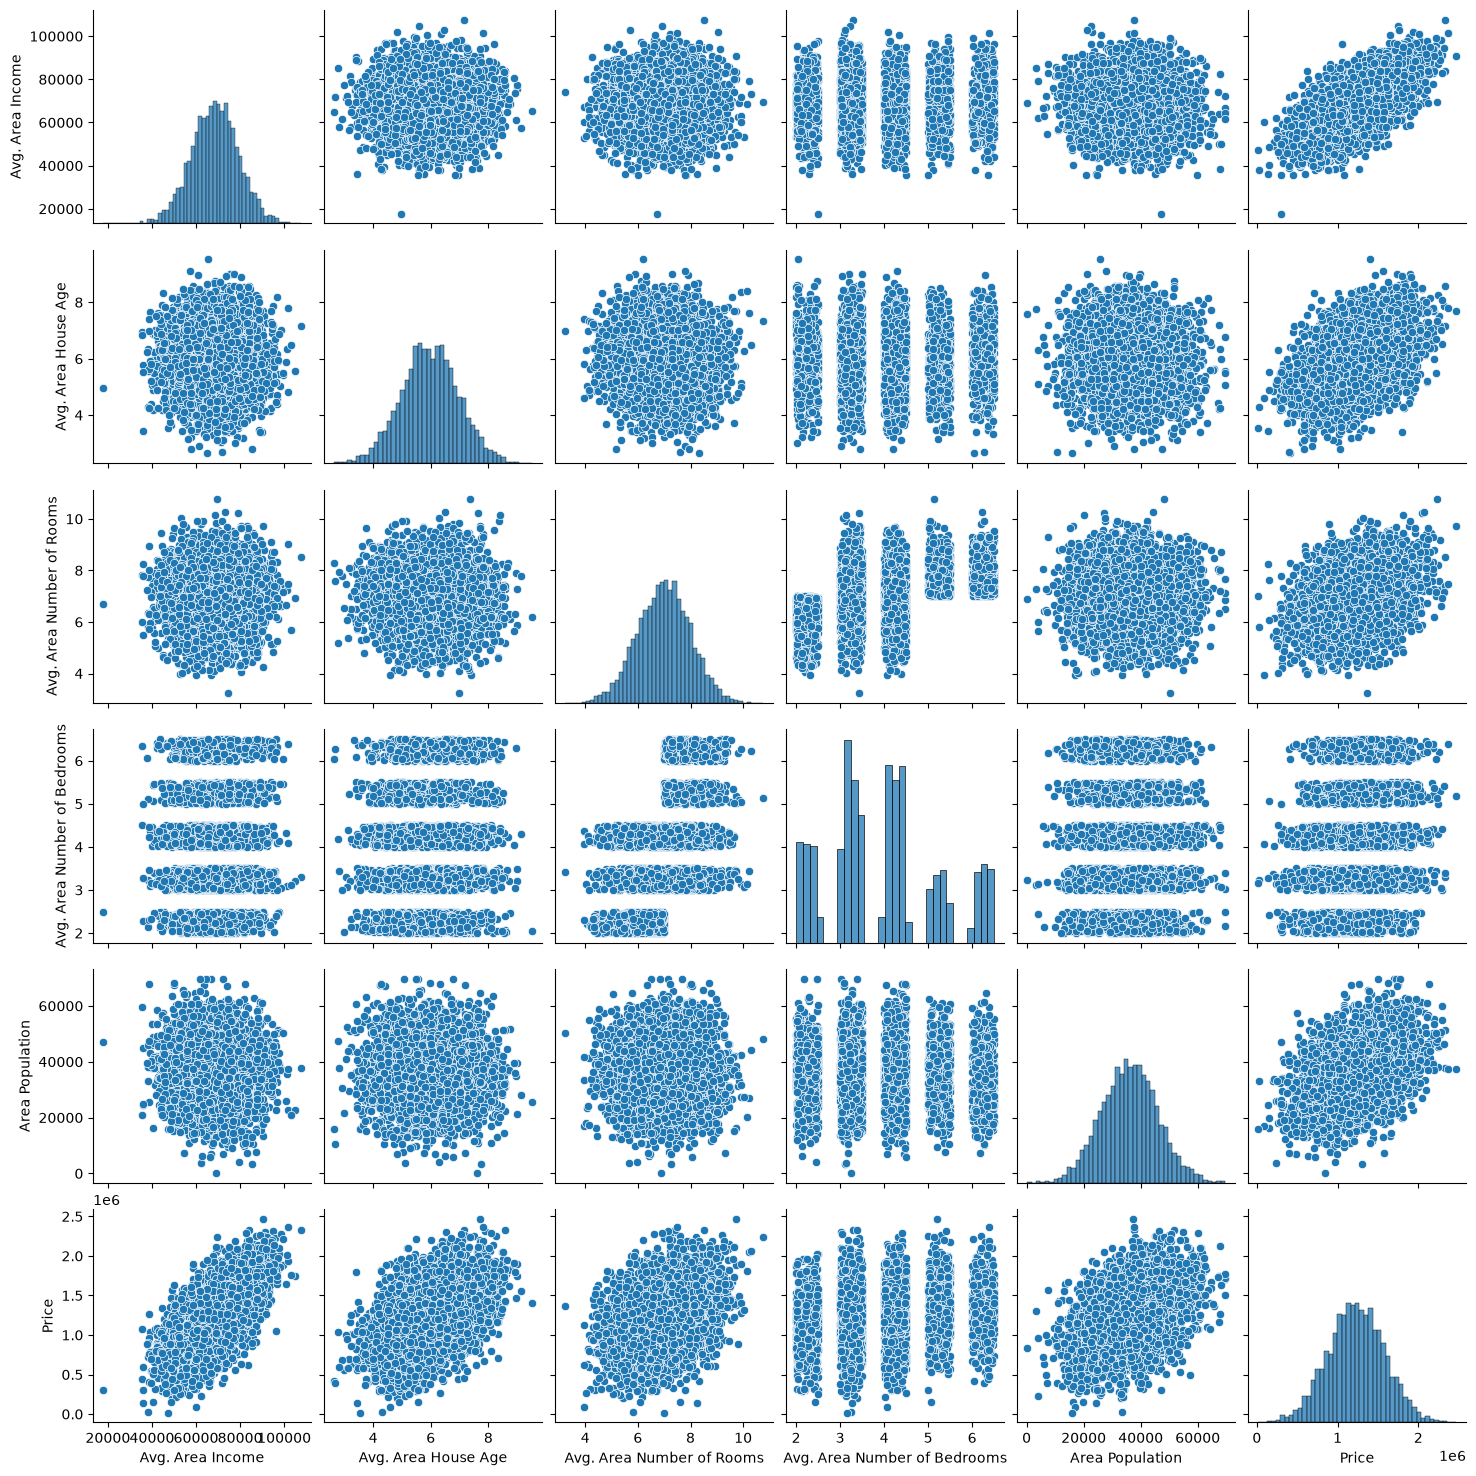

In [6]:
sns.pairplot(df)

**Distribution of price (the predicted quantity)**

<Axes: ylabel='Frequency'>

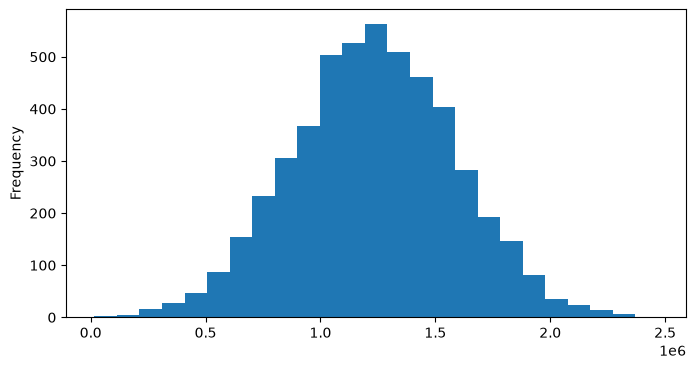

In [7]:
df['Price'].plot.hist(bins=25,figsize=(8,4))

<Axes: ylabel='Density'>

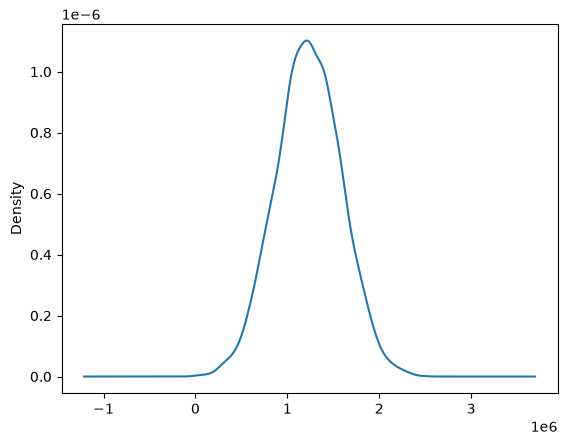

In [9]:
df['Price'].plot.density()

**Correlation matrix and heatmap**

In [10]:
df.corr(numeric_only=True)

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
Avg. Area Income,1.000000,-0.002007,-0.011032,0.019788,-0.016234,0.639734
Avg. Area House Age,-0.002007,1.000000,-0.009428,0.006149,-0.018743,0.452543
Avg. Area Number of Rooms,-0.011032,-0.009428,1.000000,0.462695,0.002040,0.335664
Avg. Area Number of Bedrooms,0.019788,0.006149,0.462695,1.000000,-0.022168,0.171071
Area Population,-0.016234,-0.018743,0.002040,-0.022168,1.000000,0.408556
Price,0.639734,0.452543,0.335664,0.171071,0.408556,1.000000


<Axes: >

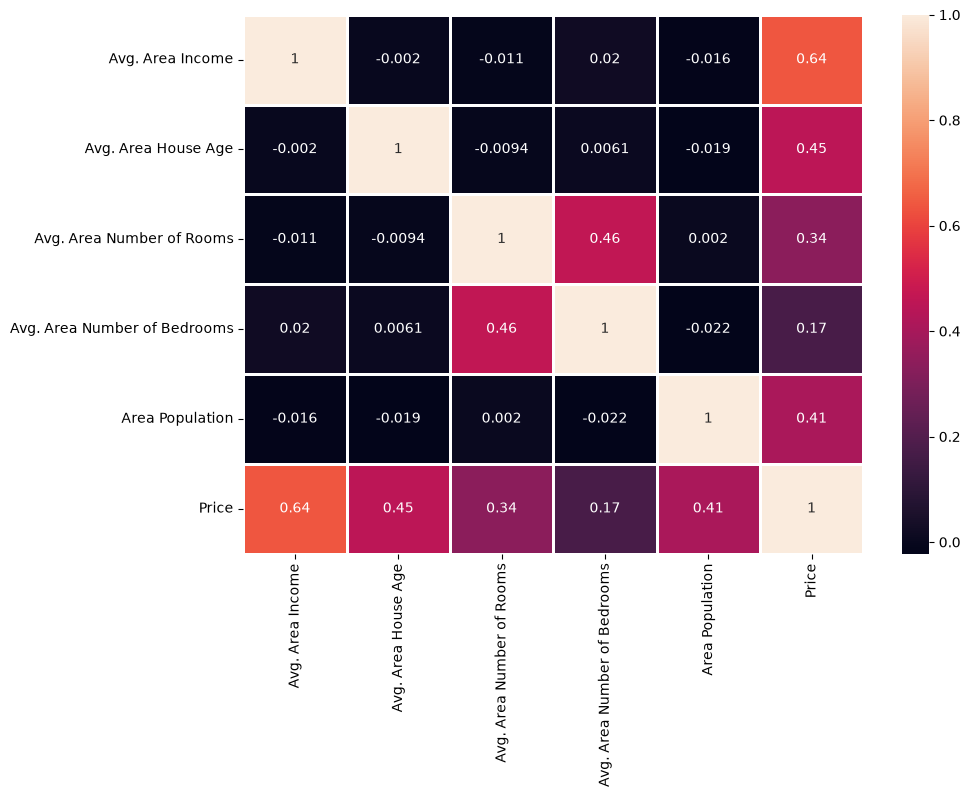

In [11]:
plt.figure(figsize=(10,7))
sns.heatmap(df.corr(numeric_only=True), annot=True, linewidths=2)

### Feature and variable sets

**Make a list of data frame column names**

In [12]:
l_column = list(df.columns) # Making a list out of column names
len_feature = len(l_column) # Length of column vector list
l_column

['Avg. Area Income',
 'Avg. Area House Age',
 'Avg. Area Number of Rooms',
 'Avg. Area Number of Bedrooms',
 'Area Population',
 'Price',
 'Address']

**Put all the numerical features in X and Price in y, ignore Address which is string for linear regression**

In [13]:
X = df[l_column[0:len_feature-2]]
y = df[l_column[len_feature-2]]

In [14]:
print("Feature set size:",X.shape)
print("Variable set size:",y.shape)

Feature set size: (5000, 5)
Variable set size: (5000,)


In [15]:
X.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population
0,79545.458574,5.682861,7.009188,4.09,23086.800503
1,79248.642455,6.002900,6.730821,3.09,40173.072174
2,61287.067179,5.865890,8.512727,5.13,36882.159400
3,63345.240046,7.188236,5.586729,3.26,34310.242831
4,59982.197226,5.040555,7.839388,4.23,26354.109472


In [16]:
y.head()

0    1.059034e+06
1    1.505891e+06
2    1.058988e+06
3    1.260617e+06
4    6.309435e+05
Name: Price, dtype: float64

### Test-train split

In [17]:
from sklearn.model_selection import train_test_split

**Create training and test splits in using a split ratio of 30%**

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)
print("Training set size:", X_train.shape, y_train.shape)
print("Test set size:", X_test.shape, y_test.shape)

Training set size: (3500, 5) (3500,)
Test set size: (1500, 5) (1500,)


### Model fit and training

**Import linear regression model estimator from scikit-learn and instantiate**

In [19]:
from sklearn.linear_model import LinearRegression
from sklearn import metrics

**Create linear regression object**

In [24]:
lm = LinearRegression()

**Fit the model on to the instantiated object itself**

In [25]:
lm.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 21.62,165221.12,121405.38, 1318.72, 15.23]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['Avg. Area Income','Avg. Area House Age','Avg. Area Number of Rooms', 'Avg. Area Number of Bedrooms','Area Population']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.641e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


**Check the intercept and coefficients**

In [26]:
print("Intercept:", lm.intercept_)
pd.DataFrame(lm.coef_, X.columns, columns=['Coefficients'])

Intercept: -2641372.6673006266


,Coefficients
Avg. Area Income,21.617635
Avg. Area House Age,165221.119872
Avg. Area Number of Rooms,121405.376596
Avg. Area Number of Bedrooms,1318.718783
Area Population,15.225196


### Calculation of standard errors and t-statistic for the coefficients

In [27]:
def metric_calculations(X_train, y_train, model): 
    # Function to calculate the standard error and the t-statistic based on the model predictions, 
    # returns a dataframe which contains the coefficients, standard error and t-statistic
    cdf = pd.DataFrame(model.coef_,X.columns,columns=['Coefficients'])
    n=X_train.shape[0]
    k=X_train.shape[1]
    dfN = n-k
    train_pred=model.predict(X_train)
    train_error = np.square(train_pred - y_train)
    sum_error=np.sum(train_error)
    se=[0,0,0,0,0]
    for i in range(k):
        r = (sum_error/dfN)
        r = r/np.sum(np.square(X_train[list(X_train.columns)[i]]-X_train[list(X_train.columns)[i]].mean()))
        se[i]=np.sqrt(r)
    cdf['Standard Error']=se
    cdf['t-statistic']=cdf['Coefficients']/cdf['Standard Error']
    return cdf

Sort the features based on the t-statistic

In [28]:
cdf = metric_calculations(X_train, y_train, lm)
cdf.sort_values(by='t-statistic', ascending=False)

,Coefficients,Standard Error,t-statistic
Avg. Area Income,21.617635,0.161636,133.742644
Avg. Area House Age,165221.119872,1751.029402,94.356565
Area Population,15.225196,0.172533,88.245039
Avg. Area Number of Rooms,121405.376596,1711.141247,70.949945
Avg. Area Number of Bedrooms,1318.718783,1392.125689,0.947270


### Prediction, error estimate, and regression evaluation matrices

**Do prediction with the linear model**

In [29]:
predictions = lm.predict(X_test)

**Plot predictions against the ground truth values**

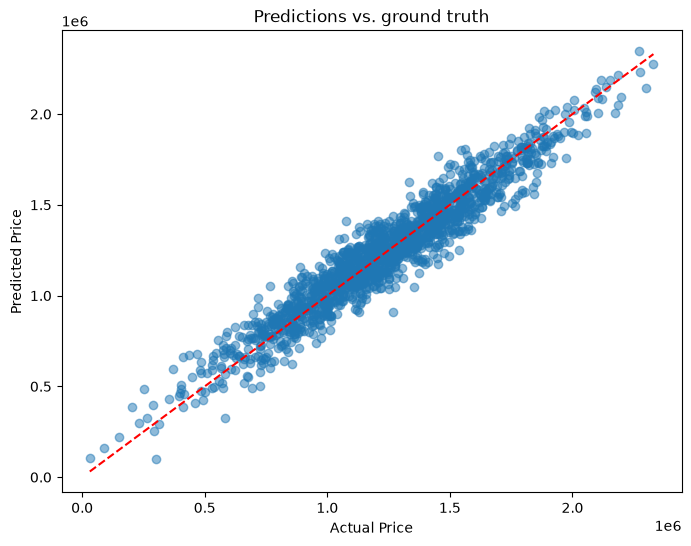

In [30]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, predictions, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Predictions vs. ground truth')
plt.show()

**What can be determined from this plot?**

The predicted prices lie close to the red diagonal line (predicted = actual). It forms a tight, roughly straight band. This means the model's predictions track the true house prices well. This agrees with the high R^2 of about 0.92 on the test set.
The spread around the line is fairly uniform across the whole price range, with no obvious curve or funnel shape, so the model does not over- or under-predict at low or high prices.


**Calculate the mean absolute, the mean squared and the root mean square errors as well as the $R^2$-value of the predictions**

In [31]:
print("Mean absolute error (MAE):", metrics.mean_absolute_error(y_test, predictions))
print("Mean squared error (MSE):", metrics.mean_squared_error(y_test, predictions))
print("Root mean squared error (RMSE):", np.sqrt(metrics.mean_squared_error(y_test, predictions)))
print("R^2 value:", metrics.r2_score(y_test, predictions))

Mean absolute error (MAE): 81257.5579585557
Mean squared error (MSE): 10169125565.89724
Root mean squared error (RMSE): 100842.08231634866
R^2 value: 0.9185060945363651


# Optional plots 
For good practice

**Plotting histogram of the residuals i.e. predicted errors (expect a normally distributed pattern)**

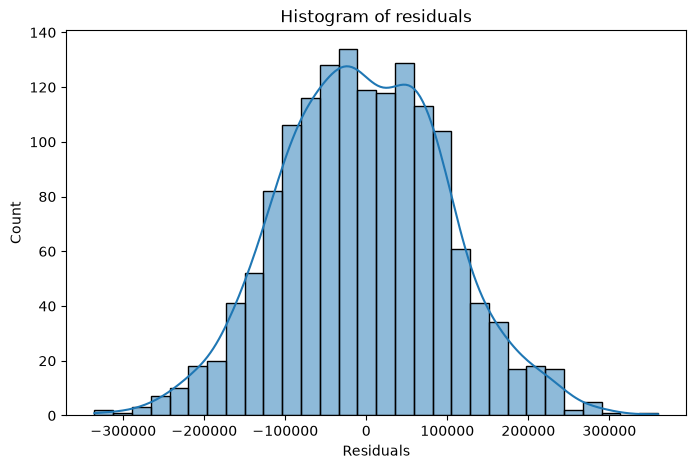

In [32]:
residuals = y_test - predictions
plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=30, kde=True)
plt.xlabel('Residuals')
plt.title('Histogram of residuals')
plt.show()

**Scatter plot of residuals vs. predicted values (Homoscedasticity)**

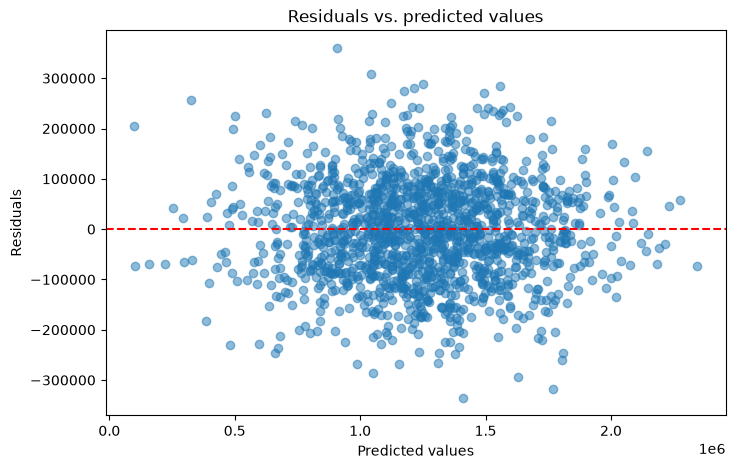

In [33]:
plt.figure(figsize=(8, 5))
plt.scatter(predictions, residuals, alpha=0.5)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel('Predicted values')
plt.ylabel('Residuals')
plt.title('Residuals vs. predicted values')
plt.show()